# Student Performance Analysis

**Project Type:** Exploratory Data Analysis (EDA)

**Technologies:** Python, Pandas, NumPy, Matplotlib, Seaborn

## Objective

The objective of this project is to analyze students' academic performance across mathematics, reading, and writing and investigate how factors such as gender, parental education, lunch category, and test preparation are associated with student scores.

## Key Research Questions

1. What is the overall academic performance of students?
2. How does performance differ across subjects?
3. Is test preparation associated with higher scores?
4. How does parental education relate to performance?
5. What relationships exist between mathematics, reading, and writing scores?

In [6]:
# Data manipulation and numerical operations
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option('display.max_columns', None)

# Visualization settings
sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
print("Dataset Shape:", df.shape)

print("Total Students:", df.shape[0])
print("Total Features:", df.shape[1])

Dataset Shape: (1000, 8)
Total Students: 1000
Total Features: 8


In [9]:

# Display all column names
print("Dataset Columns:")

for column in df.columns:
    print(column)


Dataset Columns:
gender
race/ethnicity
parental level of education
lunch
test preparation course
math score
reading score
writing score


In [10]:

# Display the last five records
df.tail()


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [12]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [13]:
df.isnull().sum()

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64

In [14]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [15]:
df.nunique()

gender                          2
race/ethnicity                  5
parental level of education     6
lunch                           2
test preparation course         2
math score                     81
reading score                  72
writing score                  77
dtype: int64

In [16]:
df["gender"].value_counts()

gender
female    518
male      482
Name: count, dtype: int64

In [17]:
df["test preparation course"].value_counts()

test preparation course
none         642
completed    358
Name: count, dtype: int64

In [18]:
df["parental level of education"].value_counts()

parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

In [19]:
print("Numerical columns:")
print(df.select_dtypes(include="number").columns.tolist())

print("\nCategorical columns:")
print(df.select_dtypes(include="object").columns.tolist())

Numerical columns:
['math score', 'reading score', 'writing score']

Categorical columns:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course']


In [20]:
score_columns = ["math score", "reading score", "writing score"]

df[score_columns].agg(["min", "max", "mean", "median"])

,math score,reading score,writing score
min,0.000,17.000,10.000
max,100.000,100.000,100.000
mean,66.089,69.169,68.054
median,66.000,70.000,69.000


In [21]:

# Keep the original data unchanged
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)


Original dataset shape: (1000, 8)
Working dataset shape: (1000, 8)


In [22]:

# Convert column names to lowercase and replace spaces with underscores
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
    .str.replace("/", "_", regex=False)
)

print(df_clean.columns.tolist())


['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


In [23]:

# Count missing values in each column
print(df_clean.isnull().sum())

# Calculate missing-value percentages
missing_percent = (
    df_clean.isnull().sum() / len(df_clean) * 100
).round(2)

print("\nMissing-value percentage:")
print(missing_percent)


gender                         0
race_ethnicity                 0
parental_level_of_education    0
lunch                          0
test_preparation_course        0
math_score                     0
reading_score                  0
writing_score                  0
dtype: int64

Missing-value percentage:
gender                         0.0
race_ethnicity                 0.0
parental_level_of_education    0.0
lunch                          0.0
test_preparation_course        0.0
math_score                     0.0
reading_score                  0.0
writing_score                  0.0
dtype: float64


In [24]:

# Total marks across all three subjects
df_clean["total_score"] = df_clean[score_columns].sum(axis=1)

# Average marks across all three subjects
df_clean["average_score"] = df_clean[score_columns].mean(axis=1).round(2)

# Inspect the new features
df_clean[
    score_columns + ["total_score", "average_score"]
].head()


KeyError: "None of [Index(['math score', 'reading score', 'writing score'], dtype='object')] are in the [columns]"

In [25]:
score_columns = [
    "math_score",
    "reading_score",
    "writing_score"
]

print(df_clean.columns.tolist())

['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score']


In [26]:
# Calculate total marks across all three subjects
df_clean["total_score"] = df_clean[score_columns].sum(axis=1)

# Calculate average marks across all three subjects
df_clean["average_score"] = (
    df_clean[score_columns].mean(axis=1).round(2)
)

# Display the results
df_clean[
    score_columns + ["total_score", "average_score"]
].head()

,math_score,reading_score,writing_score,total_score,average_score
0,72,72,74,218,72.67
1,69,90,88,247,82.33
2,90,95,93,278,92.67
3,47,57,44,148,49.33
4,76,78,75,229,76.33


In [27]:

print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum())

print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nFirst five records:")
display(df_clean.head())


Final dataset shape: (1000, 10)

Missing values:
0

Duplicate rows:
0

Column names:
['gender', 'race_ethnicity', 'parental_level_of_education', 'lunch', 'test_preparation_course', 'math_score', 'reading_score', 'writing_score', 'total_score', 'average_score']

First five records:


,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.67
1,female,group C,some college,standard,completed,69,90,88,247,82.33
2,female,group B,master's degree,standard,none,90,95,93,278,92.67
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.33
4,male,group C,some college,standard,none,76,78,75,229,76.33


In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [29]:
score_columns = [
    "math_score",
    "reading_score",
    "writing_score"
]

df_clean[score_columns].describe().round(2)

,math_score,reading_score,writing_score
count,1000.00,1000.00,1000.00
mean,66.09,69.17,68.05
std,15.16,14.60,15.20
min,0.00,17.00,10.00
25%,57.00,59.00,57.75
50%,66.00,70.00,69.00
75%,77.00,79.00,79.00
max,100.00,100.00,100.00


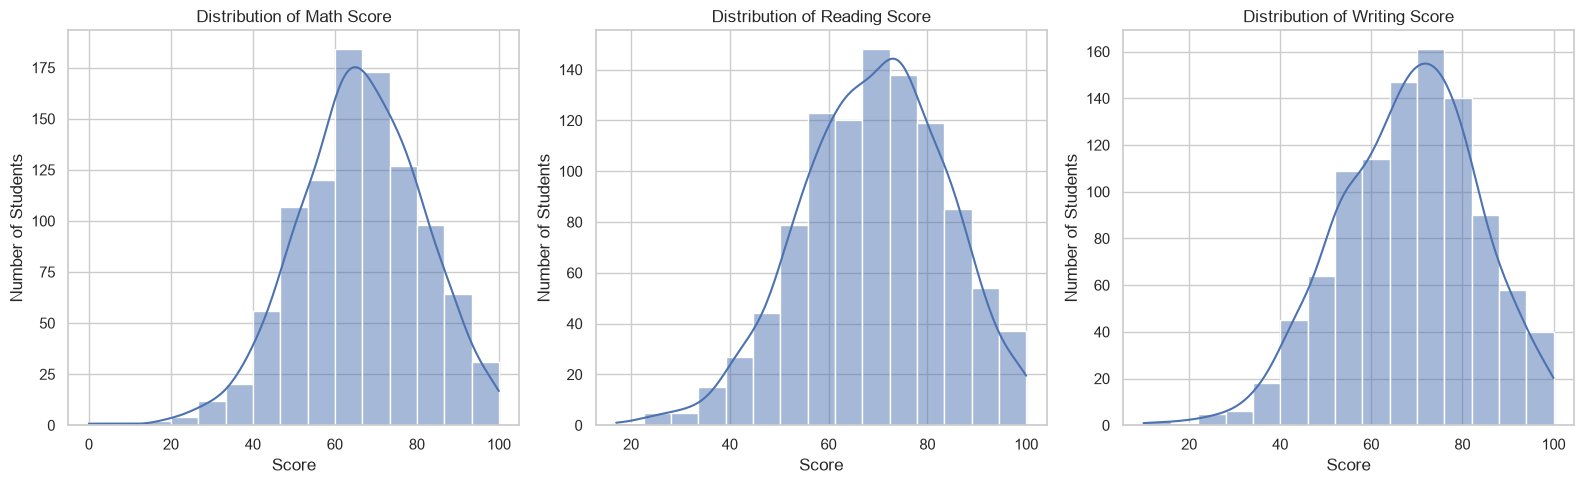

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, column in zip(axes, score_columns):
    sns.histplot(
        data=df_clean,
        x=column,
        bins=15,
        kde=True,
        ax=ax
    )
    ax.set_title(f"Distribution of {column.replace('_', ' ').title()}")
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

In [31]:
gender_analysis = (
    df_clean
    .groupby("gender")[score_columns]
    .mean()
    .round(2)
)

gender_analysis

,math_score,reading_score,writing_score
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


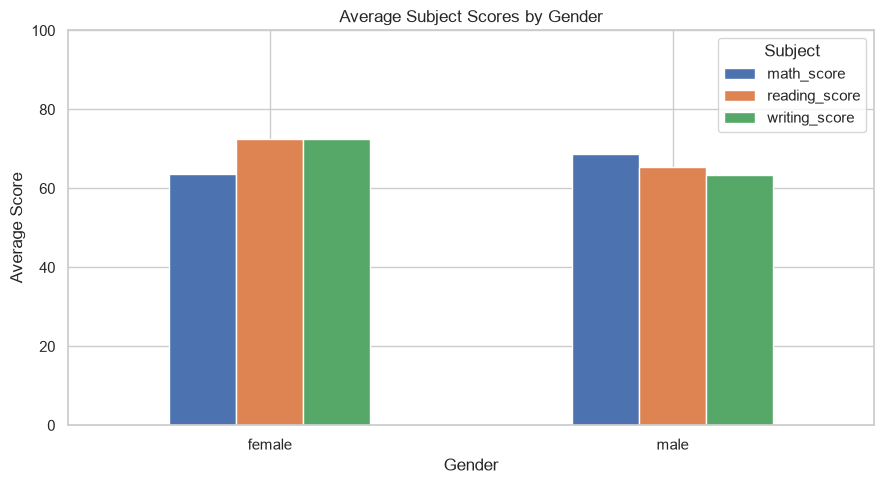

In [32]:
gender_analysis.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Average Subject Scores by Gender")
plt.xlabel("Gender")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

In [33]:
preparation_analysis = (
    df_clean
    .groupby("test_preparation_course")[score_columns + ["average_score"]]
    .mean()
    .round(2)
)

preparation_analysis

,math_score,reading_score,writing_score,average_score
test_preparation_course,,,,
completed,69.70,73.89,74.42,72.67
none,64.08,66.53,64.50,65.04


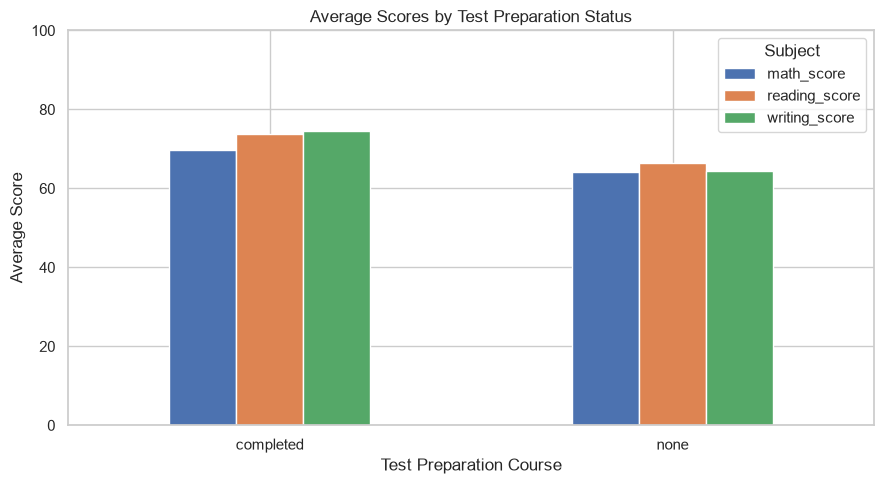

In [34]:
preparation_analysis[score_columns].plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("Average Scores by Test Preparation Status")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.legend(title="Subject")
plt.tight_layout()
plt.show()

In [35]:
score_difference = (
    preparation_analysis.loc["completed", score_columns]
    - preparation_analysis.loc["none", score_columns]
).round(2)

score_difference

math_score       5.62
reading_score    7.36
writing_score    9.92
dtype: float64

In [36]:
correlation_matrix = df_clean[score_columns].corr()

correlation_matrix.round(2)

,math_score,reading_score,writing_score
math_score,1.00,0.82,0.80
reading_score,0.82,1.00,0.95
writing_score,0.80,0.95,1.00


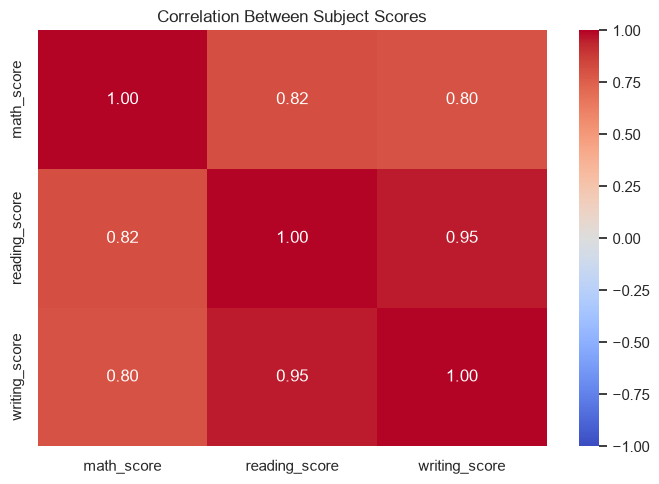

In [37]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)

plt.title("Correlation Between Subject Scores")
plt.tight_layout()
plt.show()

In [38]:
parent_education_analysis = (
    df_clean
    .groupby("parental_level_of_education")["average_score"]
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

parent_education_analysis

parental_level_of_education
master's degree       73.60
bachelor's degree     71.92
associate's degree    69.57
some college          68.48
some high school      65.11
high school           63.10
Name: average_score, dtype: float64

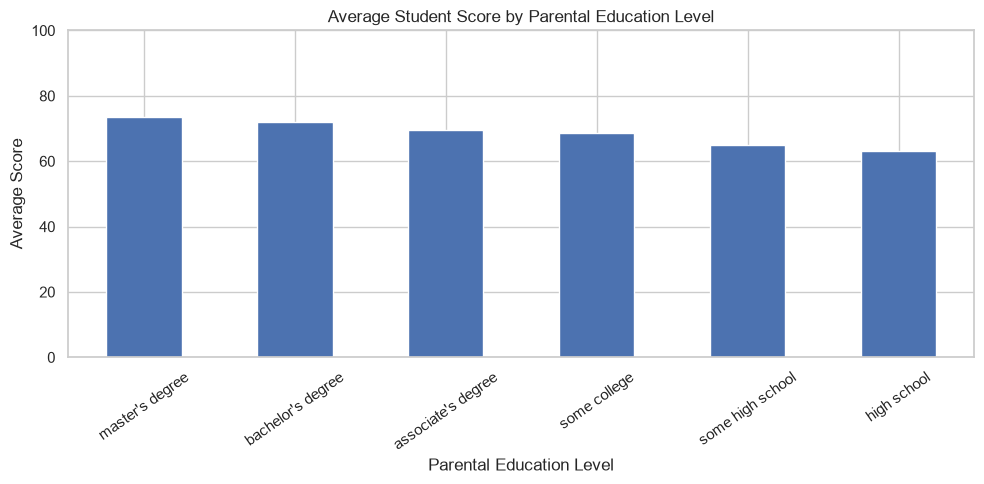

In [39]:
parent_education_analysis.plot(
    kind="bar",
    figsize=(10, 5),
    rot=35
)

plt.title("Average Student Score by Parental Education Level")
plt.xlabel("Parental Education Level")
plt.ylabel("Average Score")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()